# 🏢 PyG 그래프 신경망 네 모델 — 골조의 절점 변위와 층간변위 검토

**건설빅데이터분석 · 그래프 신경망 · PyG GNN 네 모델 (골조) · 실습 노트북 (완성본)**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/baekja/Lecture_GNN-AE-Practice/blob/main/PyG_FourGNN_Frame/frame_gnn4_practice.ipynb) ← **실습본**(빈칸 채우기) &nbsp;&nbsp;[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/baekja/Lecture_GNN-AE-Practice/blob/main/PyG_FourGNN_Frame/frame_gnn4_complete.ipynb) ← **완성본**(정답·실행결과 포함)

> 지난 실습(Cora)에서 만든 네 모델 — **VanillaGNN · GCN · GAT · GraphSAGE** — 을 건축공학 문제에 씁니다.
> 손으로 풀 수 있는 **전단빌딩 골조**(보는 강체, 기둥은 위아래 끝 고정)에서 수평하중에 의한 **절점 변위**를 맞히고, **층간변위비 1/400 검토**를 분류합니다. 정답(라벨)은 손계산 공식으로 만듭니다.
> 1경간 2층 골조 하나를 손으로 풀고 네 층의 한 단계를 손계산으로 확인한 뒤, 골조 400동을 만들어 **처음 보는 건물(귀납)** 과 **같은 건물의 다른 절점(전이)** 두 설정으로 비교합니다.

## 📌 강의 중점
- 골조 = 그래프: 절점 → 노드, 부재(기둥 · 보) → 엣지, 하중 · 강성 · 높이 → 노드 피처
- 전단빌딩 손계산: 기둥 강성 $12EI/h^3$ · 층전단력 = 위쪽 하중의 합 · 층간변위 = 층전단력 ÷ 층 강성 · 변위 = 아래부터 누적
- 네 층의 집계 규칙을 절점 하나에서 손계산 → PyG 층과 같은 값
- 지지 절점은 채점에서 빼기 · 기준점 MLP · seed 0·1·2 평균 ± 표준편차
- 전이(같은 건물 안의 다른 절점) vs 귀납(처음 보는 건물): 무엇을 나누느냐가 점수를 바꾼다

## 🎯 학습 목표
1. 골조의 절점 · 부재 · 하중을 `edge_index` 와 노드 피처로 표현하고, 전단빌딩 공식으로 절점 변위를 손계산할 수 있다.
2. 절점 하나에서 VanillaGNN · GCN · GAT · GraphSAGE 한 층을 손으로 계산하고, PyG 층과 같은 값인지 확인할 수 있다.
3. 손계산 공식을 함수로 만들어 골조 400동의 라벨을 만들고, 건물 단위로 학습 · 시험을 나눌 수 있다.
4. 다섯 모델의 변위 결정계수 $R^2$ 와 층간변위 검토 정확도를 귀납 · 전이 설정에서 비교하고 해석할 수 있다.

## 📋 이 노트북 사용법

| 표시 | 뜻 |
|:-:|---|
| ▶ | 셀 실행 — 셀을 클릭하고 `Shift + Enter` |
| 🎬 EP*n* | 이 부분을 설명하는 강의 영상 에피소드 (e-campus) |
| ⏸ | 영상을 멈추고 직접 실행해 보는 지점 |
| ✅ / ❌ | 자가검증 결과 — ❌ 가 나오면 힌트를 읽고 고쳐 보세요 |
| 🔸 | 실험 결과 안내 (오류가 아님) |

**주석(`#` 뒤의 글) 읽는 법** — 실행에는 영향이 없는 설명입니다.
- `1️⃣2️⃣3️⃣4️⃣` 학습 루프 단계 · `①②③④` 손계산 단계 · `💡` 강의노트 연결 · `📐` 텐서 모양(shape) · `⚠️` 흔한 실수 · `✅` 기대 결과 · `⏱` 걸린 시간

**Colab에서 처음 열었다면**
1. 메뉴 **파일 → Drive에 사본 저장** 을 먼저 누르세요. (사본에서 작업해야 내 Drive에 저장됩니다)
2. 첫 코드 셀이 PyTorch Geometric(PyG)이 없으면 설치합니다 (Colab 에서 10초 안쪽). **CPU 런타임 그대로** 모든 셀이 실행됩니다. Colab CPU 에서 노트북 전체가 **약 2분** 걸립니다 (4장의 비교 셀이 25초 안팎씩, 5장의 비교 셀이 약 1분). Colab 의 PyTorch 버전에 따라 소수점 아래 숫자가 영상과 조금 다를 수 있지만 비교 결론은 같습니다.
3. 위에서부터 **차례대로** 실행하세요. 런타임이 초기화되어 변수가 사라지면 처음부터 다시 실행하면 됩니다.

**🎬 영상과 함께 보는 법 (반복 학습 추천 순서)**
1회차 영상 전체 보기 → 2회차 실습본을 열고 ⏸ 마다 멈추며 따라 치기 → 3회차 영상 없이 빈칸 채우기 → 모든 ✅ 통과 → 끝의 🏆 도전 과제

---
## 0. 준비 — PyG 설치와 라이브러리  🎬 EP1

이 셀에서 할 일: **PyTorch Geometric(PyG)** 이 없으면 설치하고, 오늘 쓸 도구를 불러옵니다. 지난 실습과 같고, 골조 라벨 계산에 쓸 `numpy` 와 여러 그래프를 묶는 `Batch` 가 더해졌습니다.

In [1]:
import importlib.util, subprocess                      # 설치 확인 · 명령 실행 도구
if importlib.util.find_spec("torch_geometric") is None:  # PyG 가 없으면 (Colab 처음 실행)
    subprocess.run(["pip", "install", "-q", "torch_geometric"], check=True)  # 설치
print("PyG 준비 완료")                                 # 이미 있으면 바로 여기로

PyG 준비 완료


In [2]:
import time                                            # 걸린 시간 재기 (⏱)
import numpy as np                                     # 골조 라벨 계산 (배열 연산)
import torch                                           # PyTorch: 텐서와 신경망
from torch import nn                                   # nn = 신경망 부품(층) 모음
import torch.nn.functional as F                        # F = 렐루 · 손실 함수
import torch_geometric                                 # PyG 본체 (seed 고정 함수)
from torch_geometric.data import Data, Batch           # 그래프 하나 · 여러 그래프 묶음
from torch_geometric.nn import GCNConv, GATConv, SAGEConv     # PyG 가 만들어 둔 GNN 층
from torch_geometric.utils import to_dense_adj, to_undirected  # 그래프 도구
import pandas as pd                                    # 결과 표
import matplotlib.pyplot as plt                        # 그림 그리기

torch.set_printoptions(precision=4, sci_mode=False)    # 소수 4자리, 지수 표기 끄기
print("PyTorch", torch.__version__, "· PyG", torch_geometric.__version__)  # 버전 확인

PyTorch 2.9.1 · PyG 2.7.0


### 자가검증 도우미 `check()` · `check_range()` 준비
아래 셀은 결과가 맞는지 ✅ / ❌ 로 알려 주는 **도우미 함수**입니다. 지난 실습과 같습니다 — **실행만** 해 두세요.

In [3]:
def check(name, value, expected, tol=0.01):  # 자가검증 (이름, 결과, 기대값, 허용오차)
    """value 가 expected 와 tol 이내로 같으면 ✅, 다르면 ❌ 를 보여 줍니다."""
    value = torch.as_tensor(value, dtype=torch.float32)        # 숫자·리스트 → 텐서
    expected = torch.as_tensor(expected, dtype=torch.float32)  # 기대값도 텐서로
    if value.shape != expected.shape:                          # ⚠️ 모양부터 다르면
        print(f"❌ {name}: 모양 {tuple(value.shape)} ≠ 기대 {tuple(expected.shape)}")
        return                                                 # 여기서 끝
    gap = (value - expected).abs().max().item()                # 가장 큰 차이
    mark = "✅" if gap <= tol else "❌"                         # 허용오차 안이면 통과
    tol_s = f"{tol:.6f}".rstrip("0").rstrip(".")               # 0.000001 처럼 보기 좋게
    print(f"{mark} {name}: 최대 차이 {gap:.6f} (허용 {tol_s})")  # 결과 출력

def check_range(name, value, lo, hi):        # 자가검증 (이름, 결과, 최솟값, 최댓값)
    """value 가 lo ~ hi 범위 안이면 ✅, 벗어나면 ❌ 를 보여 줍니다."""
    value = float(value)                                       # 텐서·숫자 → 파이썬 실수
    mark = "✅" if lo <= value <= hi else "❌"                  # 범위 안이면 통과
    print(f"{mark} {name}: {value:.4f} (기대 범위 {lo} ~ {hi})")  # 결과 출력

---
## 1. 손으로 푸는 골조 — 1경간 2층 전단빌딩

이 셀에서 할 일: 수평하중을 받는 **1경간 2층 골조**의 절점 변위를 손계산 공식으로 구합니다. 이 공식이 3장에서 골조 400동의 **정답(라벨)** 을 만듭니다.
- **전단빌딩 가정**: 보는 휘지 않는 강체이고, 기둥은 위아래 끝이 고정입니다. 그러면 기둥 하나의 수평 강성은 $k = 12EI/h^3$ 입니다.
- **층전단력** $V$ = 그 층의 위쪽 레벨들에 걸린 수평하중의 합 · **층간변위** $\delta = V / \sum k$ (그 층 기둥들의 강성 합) · **절점 변위** $u$ = 아래층부터 $\delta$ 를 누적
- 예제: 층고 $h$ = 3 m, $EI$ = 22,500 kN·m² → $k = 12 \times 22{,}500 / 3^3$ = 10,000 kN/m = **10 kN/mm** (기둥 하나). 수평하중은 레벨 1(2층 바닥) 10 kN, 지붕 20 kN.

| 층 | 층전단력 $V$ | 층 강성 $\sum k$ | 층간변위 $\delta$ | 절점 변위 $u$ |
|:-:|:-:|:-:|:-:|:-:|
| 1층 | 10 + 20 = 30 kN | 2 × 10 = 20 kN/mm | 1.5 mm | **1.5 mm** |
| 2층 | 20 kN | 20 kN/mm | 1.0 mm | **2.5 mm** |

> 💡 **새 파이썬 문법 — 거꾸로 누적합 `np.cumsum(a[::-1])[::-1]`**
>
> `a[::-1]` 은 배열을 뒤집습니다. 뒤집어서 누적합을 구하고 다시 뒤집으면 "나와 내 위쪽의 합"이 됩니다: `[10, 20]` → `[30, 20]`.

In [4]:
h, EI = 3.0, 22_500.0                                  # 층고 (m), 기둥 휨강성 EI (kN·m²)
k_col = 12 * EI / h**3 / 1000                # 기둥 하나의 강성 (kN/mm)
F_lv = np.array([10.0, 20.0])                          # 레벨 1 · 지붕의 수평하중 (kN)
V = np.cumsum(F_lv[::-1])[::-1]                        # 층전단력 = 위쪽 하중의 합 (kN)
drift = V / (2 * k_col)                                # 층간변위 = V ÷ 기둥 2개의 강성 (mm)
u = np.cumsum(drift)                                   # 절점 변위 = 아래부터 누적 (mm)
print("k =", k_col, "kN/mm · V =", V, "kN · δ =", drift, "mm · u =", u, "mm")  # 손계산 표
check("u = [1.5, 2.5] mm", u, [1.5, 2.5], tol=1e-9)    # ✅ 손계산

k = 10.0 kN/mm · V = [30. 20.] kN · δ = [1.5 1. ] mm · u = [1.5 2.5] mm
✅ u = [1.5, 2.5] mm: 최대 차이 0.000000 (허용 0)


### 1-1. 골조를 그래프로 — 절점은 노드, 부재는 엣지 ⏸
- 절점 번호: **0, 1 = 지지**(바닥) · **2, 3 = 레벨 1** · **4, 5 = 지붕** (왼쪽 → 오른쪽)
- 부재 6개: 기둥 4개(0–2, 1–3, 2–4, 3–5) + 보 2개(2–3, 4–5) → 양방향 엣지 12개
- 노드 피처(2개): **[지지 여부, 절점 하중 kN]** — 한 레벨의 하중은 그 레벨의 절점들이 나눠 받습니다.
- 강체 보라서 **같은 레벨의 두 절점은 변위가 같습니다.**

In [5]:
members = [(0, 2), (1, 3), (2, 4), (3, 5),            # 기둥 4개 (아래 절점, 위 절점)
           (2, 3), (4, 5)]                             # 보 2개 (레벨 1 · 지붕)
ei = to_undirected(torch.tensor(members).t())  # 양방향 📐 [2, 12]
x = torch.tensor([[1., 0], [1, 0],                     # 피처 [지지?, 절점 하중 kN] — 지지 2개
                  [0, 5], [0, 5],                      # 레벨 1: 10 kN 을 두 절점이 5 kN 씩
                  [0, 10], [0, 10]])                   # 지붕: 20 kN 을 10 kN 씩
y = torch.tensor([0, 0, 1.5, 1.5, 2.5, 2.5])           # 정답: 절점 변위 u (mm), 지지는 0
g = Data(x=x, edge_index=ei, y=y)                      # PyG 그래프 하나
print(g)                                               # 📐 노드 6 · 엣지 12 · 피처 2
check("정답 y = 손계산 u", y[[2, 4]], u, tol=1e-6)      # ✅ 레벨 1 · 지붕

Data(x=[6, 2], edge_index=[2, 12], y=[6])
✅ 정답 y = 손계산 u: 최대 차이 0.000000 (허용 0.000001)


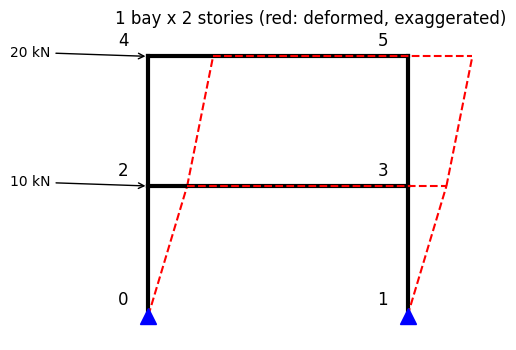

In [6]:
xy = np.array([[0, 0], [6, 0], [0, 3], [6, 3], [0, 6], [6, 6]], float)  # 절점 좌표 (m), 경간 6 m
moved = xy + np.stack([y.numpy() * 0.6, np.zeros(6)], axis=1)  # 변위 과장 (1 mm → 0.6 m)
plt.figure(figsize=(4.6, 4))                           # 그림 크기
for a, b in members:                                   # 부재마다
    plt.plot(*xy[[a, b]].T, "k-", lw=3)                # 원래 골조 (검정)
    plt.plot(*moved[[a, b]].T, "r--", lw=1.5)          # 변형된 모양 (빨강 점선, 과장)
for j, (px, py) in enumerate(xy):                      # 절점 번호 쓰기
    plt.text(px - 0.7, py + 0.25, str(j), fontsize=12)  # 번호
for py, f in ((3, 10), (6, 20)):                       # 수평하중 화살표
    plt.annotate(f"{f} kN", (0, py), (-3.2, py), arrowprops={"arrowstyle": "->"})  # 하중
plt.plot(xy[:2, 0], xy[:2, 1], "b^", ms=12)            # 지지 (파랑 삼각형)
plt.title("1 bay x 2 stories (red: deformed, exaggerated)")  # 영문 제목
plt.axis("equal"); plt.axis("off"); plt.show()         # 비율 같게 · 축 숨김 · 그리기

---
## 2. 절점 2 에서 네 층을 손으로, 그리고 코드로  🎬 EP2

절점 2 (레벨 1 왼쪽)의 이웃은 **0 (아래 지지) · 3 (보) · 4 (위 기둥)** 입니다. 같은 이웃을 네 모델이 어떻게 섞는지 손으로 계산하고 PyG 층과 비교합니다. 가중치는 모두 단위행렬 $W = I$ 로 둡니다.

| 모델 | 절점 2 의 한 층 (손계산) |
|---|---|
| VanillaGNN $\tilde A X$ | $x_0 + x_2 + x_3 + x_4 = [1,0] + [0,5] + [0,5] + [0,10] = [1, 20]$ |
| GCN $\hat A X$ | 계수 $1/\sqrt{\tilde d_2 \tilde d_j}$ ($\tilde d$: 0 → 2, 2 → 4, 3 → 4, 4 → 3): .354 · .250 · .250 · .289 → $[0.354, 5.387]$ |
| GAT | $a_{\text{dst}} = [0, 0.1]$, $a_{\text{src}} = [0, 0.2]$ → 점수 0.5 · 1.5 · 1.5 · 2.5 → $\alpha$ = .072 · .197 · .197 · .534 → $[0.072, 7.311]$ |
| GraphSAGE | $0.4\,x_2 + 0.6 \cdot \mathrm{mean}(x_0, x_3, x_4) = 0.4\,[0, 5] + 0.6\,[1/3, 5] = [0.2, 5.0]$ |

In [7]:
A = to_dense_adj(ei)[0]                                # 인접행렬 📐 [6, 6]
A_tilde = A + torch.eye(6)                             # 자기 루프 더하기 (Ã = A + I)
print("절점 2 의 닫힌 이웃:", A_tilde[2].nonzero().flatten().tolist())  # 0 · 2 · 3 · 4
van = A_tilde @ x                            # VanillaGNN 한 층 (W = I)
print("Vanilla 절점 2:", van[2])                       # 이웃 + 자기의 합
check("Vanilla 절점 2 = [1, 20]", van[2], [1., 20.], tol=0)  # ✅ 손계산

절점 2 의 닫힌 이웃: [0, 2, 3, 4]
Vanilla 절점 2: tensor([ 1., 20.])
✅ Vanilla 절점 2 = [1, 20]: 최대 차이 0.000000 (허용 0)


In [8]:
deg = A_tilde.sum(dim=1)                               # 자기 루프 포함 차수 d̃
D_inv_sqrt = torch.diag(deg.pow(-0.5))       # D̃^(-1/2)
A_hat = D_inv_sqrt @ A_tilde @ D_inv_sqrt              # Â = D̃^-1/2 Ã D̃^-1/2
print("d̃ =", deg.tolist(), "\n절점 2 의 계수:", A_hat[2])  # 0 · 2 · 3 · 4 열에만 값
gcn = GCNConv(2, 2, bias=False)                        # PyG GCN 층
with torch.no_grad():                                  # 가중치를 손으로 넣고 계산
    gcn.lin.weight.copy_(torch.eye(2))                 # W = I
    out_gcn = gcn(x, ei)                               # edge_index 만 넣으면 정규화는 안에서
check("GCN 손계산 절점 2", (A_hat @ x)[2], [0.3536, 5.3868], tol=1e-3)  # ✅
check("GCNConv = 손계산 Â X (6 × 2 전부)", out_gcn, A_hat @ x, tol=1e-5)  # ✅

d̃ = [2.0, 2.0, 4.0, 4.0, 3.0, 3.0] 
절점 2 의 계수: tensor([0.3536, 0.0000, 0.2500, 0.2500, 0.2887, 0.0000])
✅ GCN 손계산 절점 2: 최대 차이 0.000049 (허용 0.001)
✅ GCNConv = 손계산 Â X (6 × 2 전부): 최대 차이 0.000000 (허용 0.00001)


In [9]:
a_dst, a_src = torch.tensor([0, 0.1]), torch.tensor([0, 0.2])  # 받는 쪽 · 주는 쪽 가중치
nbr = [0, 2, 3, 4]                                     # 절점 2 의 닫힌 이웃
score = a_dst @ x[2] + x[nbr] @ a_src                  # ① 원점수: 하중이 큰 이웃일수록 크다
alpha = torch.softmax(F.leaky_relu(score, 0.2), dim=0)  # ② LeakyReLU → ③ 소프트맥스
h2 = alpha @ x[nbr]                                    # ④ 가중합
print("점수:", score, "\nα (0, 2, 3, 4):", alpha, "\nh'_2 =", h2)  # 절점 4 가 가장 크다
gat = GATConv(2, 2, heads=1, bias=False)               # PyG GAT 층 (헤드 1개)
with torch.no_grad():                                  # 가중치를 손으로 넣고 계산
    gat.lin.weight.copy_(torch.eye(2))                 # W = I
    gat.att_dst.copy_(a_dst.view(1, 1, 2))             # 📐 [1, 헤드 1, 출력 2]
    gat.att_src.copy_(a_src.view(1, 1, 2))             # 📐 같은 모양
    out_gat = gat(x, ei)                               # 노드 6개 모두
check("GAT 손계산 절점 2", h2, [0.0723, 7.3106], tol=1e-3)  # ✅
check("GATConv = 손계산 (절점 2)", out_gat[2], h2, tol=1e-5)  # ✅

점수: tensor([0.5000, 1.5000, 1.5000, 2.5000]) 
α (0, 2, 3, 4): tensor([0.0723, 0.1966, 0.1966, 0.5344]) 
h'_2 = tensor([0.0723, 7.3106])
✅ GAT 손계산 절점 2: 최대 차이 0.000029 (허용 0.001)
✅ GATConv = 손계산 (절점 2): 최대 차이 0.000000 (허용 0.00001)


In [10]:
mean_nbr = x[[0, 3, 4]].mean(dim=0)          # 이웃 평균
h_sage = 0.4 * x[2] + 0.6 * mean_nbr                   # 자기 0.4 + 이웃 평균 0.6
sage = SAGEConv(2, 2)                                  # PyG SAGE 층 (기본 집계 = 평균)
with torch.no_grad():                                  # 가중치를 손으로 넣고 계산
    sage.lin_r.weight.copy_(0.4 * torch.eye(2))        # W_self: 자기 피처 쪽
    sage.lin_l.weight.copy_(0.6 * torch.eye(2))        # W_nbr: 이웃 평균 쪽
    sage.lin_l.bias.zero_()                            # 편향은 0 으로
    out_sage = sage(x, ei)                             # 노드 6개 모두
check("SAGE 손계산 절점 2 = [0.2, 5.0]", h_sage, [0.2, 5.0], tol=1e-6)  # ✅
check("SAGEConv = 손계산 (절점 2)", out_sage[2], h_sage, tol=1e-5)  # ✅

✅ SAGE 손계산 절점 2 = [0.2, 5.0]: 최대 차이 0.000000 (허용 0.000001)
✅ SAGEConv = 손계산 (절점 2): 최대 차이 0.000000 (허용 0.00001)


In [11]:
four = {"Vanilla": van[2], "GCN": out_gcn[2], "GAT": out_gat[2], "SAGE": out_sage[2]}  # 절점 2
rows = {name: [round(v, 3) for v in t.tolist()] for name, t in four.items()}  # 소수 3자리로
pd.DataFrame(rows, index=["지지 채널", "하중 채널"]).T  # 행 = 모델, 열 = 피처 채널

,지지 채널,하중 채널
Vanilla,1.000,20.000
GCN,0.354,5.387
GAT,0.072,7.311
SAGE,0.200,5.000


🔍 **결과 읽는 법** — 이웃도 피처도 같은데 네 층의 결과가 다릅니다. **무엇을 얼마나 섞느냐(집계 규칙)** 가 모델의 차이입니다.
- VanillaGNN 은 그냥 더해서 값이 큽니다 (이웃이 많을수록 커짐). GCN 은 차수로 나눠 작아졌습니다.
- GAT 는 하중이 큰 위쪽 절점 4 에 계수 .534 를 주었습니다 — **피처가 계수를 정합니다.**
- GraphSAGE 는 자기 피처와 이웃 평균을 따로 섞습니다.

---
## 3. 골조 400동 만들기 — 손계산 공식이 라벨 생성기  🎬 EP3

1장의 손계산을 **함수 세 개**로 만들어, 크기와 재료가 다른 골조를 많이 만듭니다.
- `frame_edges(nb, ns)` : nb 경간 × ns 층 골조의 부재 → `edge_index` (절점 번호 = 레벨 × (nb + 1) + 기둥 줄)
- `frame_labels(...)` : 1장의 공식 그대로 → 기둥 강성 · 절점 변위 · 층간변위비 1/400 초과 여부 (층마다 $h$, $EI$ 가 달라도 됩니다)
- `make_frame(...)` : 노드 피처 4개 **[지지 여부, 절점 하중 kN, 아래층 기둥 강성 kN/mm, 높이 m]** 와 정답 두 개(변위 `y`, 검토 `c`)를 담은 PyG `Data`

In [12]:
def frame_edges(nb, ns):                               # nb 경간 × ns 층 → 부재 edge_index
    nid = lambda i, k: k * (nb + 1) + i                # 절점 번호: 레벨 k, 기둥 줄 i
    cols = [(nid(i, k), nid(i, k + 1)) for k in range(ns) for i in range(nb + 1)]  # 기둥
    beams = [(nid(i, k), nid(i + 1, k)) for k in range(1, ns + 1) for i in range(nb)]  # 보
    return to_undirected(torch.tensor(cols + beams).t())  # 양방향 edge_index
check("1경간 2층 = 1장의 부재", frame_edges(1, 2), ei, tol=0)  # ✅ 같은 엣지 12개

✅ 1경간 2층 = 1장의 부재: 최대 차이 0.000000 (허용 0)


In [13]:
LIMIT = 1 / 400                                        # 층간변위비 허용 한계
def frame_labels(nb, ns, h, EI, F_lv):                 # 1장의 손계산 공식 (층마다 h, EI 배열)
    k_col = 12 * EI / h**3 / 1000                      # 기둥 하나의 강성 (kN/mm), 층마다
    V = np.cumsum(F_lv[::-1])[::-1]          # 층전단력 (kN)
    drift = V / ((nb + 1) * k_col)           # 층간변위 (mm)
    u = np.r_[0, np.cumsum(drift)]                     # 레벨 0 ~ ns 의 변위 (mm), 바닥은 0
    over = drift / (h * 1000) > LIMIT                  # 층간변위비 δ/h 가 1/400 을 넘는 층
    return k_col, u, over                              # 강성 · 변위 · 검토 결과

In [14]:
def make_frame(nb, ns, h, EI, F_lv):                   # 골조 하나 → PyG Data
    k_col, u, over = frame_labels(nb, ns, h, EI, F_lv)  # 라벨은 손계산 공식으로
    lev = np.repeat(np.arange(ns + 1), nb + 1)   # 절점의 레벨 (0 = 지지)
    load = np.r_[0, F_lv / (nb + 1)]                   # 레벨별 절점 하중 (kN), 레벨 0 은 0
    kk, z = np.r_[0, k_col], np.r_[0, np.cumsum(h)]    # 레벨별 아래층 기둥 강성 · 높이 (m)
    feat = np.stack([lev == 0, load[lev], kk[lev], z[lev]], axis=1)  # 피처 4개 📐 [절점, 4]
    return Data(x=torch.tensor(feat, dtype=torch.float),      # [지지?, 하중, 강성, 높이]
                edge_index=frame_edges(nb, ns),               # 부재 = 엣지
                y=torch.tensor(u[lev], dtype=torch.float),    # 정답 1: 절점 변위 (mm)
                c=torch.tensor(np.r_[0, over][lev], dtype=torch.long),  # 정답 2: 1 = 1/400 초과
                lev=torch.tensor(lev))                        # 레벨 (0 = 지지)

In [15]:
hand = make_frame(nb=1, ns=2, h=np.array([3.0, 3.0]),  # 1장의 골조: 1경간 2층, 층고 3 m
                  EI=np.array([22500.0, 22500.0]),     # 기둥 EI (kN·m²)
                  F_lv=np.array([10.0, 20.0]))         # 레벨 1 · 지붕 하중 (kN)
print(hand)                                            # 📐 x=[6, 4] — 피처가 4개로
print(hand.x)                                          # [지지?, 하중, 강성, 높이]
check("make_frame 변위 = 손계산", hand.y, [0, 0, 1.5, 1.5, 2.5, 2.5], tol=1e-6)  # ✅
check("1/400 초과 절점 수 = 0", hand.c.sum(), 0, tol=0)  # ✅ δ/h = 1.5/3000 = 1/2000

Data(x=[6, 4], edge_index=[2, 12], y=[6], c=[6], lev=[6])
tensor([[ 1.,  0.,  0.,  0.],
        [ 1.,  0.,  0.,  0.],
        [ 0.,  5., 10.,  3.],
        [ 0.,  5., 10.,  3.],
        [ 0., 10., 10.,  6.],
        [ 0., 10., 10.,  6.]])
✅ make_frame 변위 = 손계산: 최대 차이 0.000000 (허용 0.000001)
✅ 1/400 초과 절점 수 = 0: 최대 차이 0.000000 (허용 0)


### 3-1. 무작위 골조 400동 ⏸
- 경간 1~3, 층수 1~5 · 층고 3 / 3.5 / 4 m · 기둥 $EI$ 1.0 / 1.5 / 2.25 × 10⁴ kN·m² (층마다 무작위) · 레벨 하중 20~60 kN
- `np.random.default_rng(0)` 으로 seed 를 고정해 늘 같은 400동이 나옵니다.

In [16]:
rng = np.random.default_rng(0)                         # 늘 같은 400동 (seed 0)
def random_frame():                                    # 무작위 골조 하나
    nb, ns = int(rng.integers(1, 4)), int(rng.integers(1, 6))  # 1~3 경간 × 1~5 층
    h = rng.choice([3.0, 3.5, 4.0], ns)                # 층고 (m), 층마다
    EI = rng.choice([1.0e4, 1.5e4, 2.25e4], ns)        # 기둥 EI (kN·m²), 층마다
    F_lv = rng.uniform(20, 60, ns)                     # 레벨 하중 (kN), 20 ~ 60
    return make_frame(nb, ns, h, EI, F_lv)             # 손계산 공식으로 라벨까지
frames = [random_frame() for _ in range(400)]  # 골조 400동

In [17]:
free_c = torch.cat([f.c[f.lev > 0] for f in frames])   # 지지가 아닌 절점의 검토 결과
free_y = torch.cat([f.y[f.lev > 0] for f in frames])   # 지지가 아닌 절점의 변위 (mm)
n_all = sum(f.num_nodes for f in frames)               # 전체 절점 수
print("골조", len(frames), "동 · 절점", n_all, "개 · 지지 제외", len(free_y), "개")  # 크기
print(f"변위 {free_y.min():.1f} ~ {free_y.max():.1f} mm")  # 가장 작은 · 큰 변위
print(f"1/400 초과 비율 {free_c.float().mean():.1%}")  # 검토 결과가 '초과'인 절점의 비율

골조 400 동 · 절점 4797 개 · 지지 제외 3604 개
변위 0.5 ~ 141.0 mm
1/400 초과 비율 33.7%


### 3-2. 건물 단위로 나누기 — 학습 280동 · 검증 60동 · 시험 60동
**귀납 설정**: 시험 건물 60동은 학습 때 **한 번도 보지 않은 건물**입니다. 여러 골조를 `Batch` 로 묶으면 서로 떨어진 그래프 여러 개가 큰 그래프 하나가 됩니다(조각 사이에는 엣지가 없음).
- 피처와 변위는 **학습 건물의 평균 · 표준편차**로 표준화합니다 (시험 건물을 미리 보지 않도록). 검증 60동은 설정을 고를 때 쓰는 몫으로 남겨 둡니다.

In [18]:
ids = torch.randperm(400, generator=torch.Generator().manual_seed(0)).tolist()  # 건물 순서 섞기
train_f = [frames[i] for i in ids[:280]]               # 학습 280동
val_f = [frames[i] for i in ids[280:340]]              # 검증 60동 (오늘은 쓰지 않음)
test_f = [frames[i] for i in ids[340:]]                # 시험 60동 — 처음 보는 건물
bt_tr = Batch.from_data_list(train_f)  # 학습 건물 → 그래프 하나
bt_te = Batch.from_data_list(test_f)   # 시험 건물도 하나로
print("학습", bt_tr.num_graphs, "동 ·", bt_tr.num_nodes, "절점")  # 떨어진 그래프 280개
print("시험", bt_te.num_graphs, "동 ·", bt_te.num_nodes, "절점")  # 처음 보는 건물 60동

학습 280 동 · 3379 절점
시험 60 동 · 686 절점


In [19]:
mx, sx = bt_tr.x.mean(dim=0), bt_tr.x.std(dim=0)       # 피처 평균 · 표준편차 (학습 건물에서만)
free_tr = bt_tr.lev > 0                                # 지지가 아닌 학습 절점
my, sy = bt_tr.y[free_tr].mean(), bt_tr.y[free_tr].std()  # 변위의 평균 · 표준편차 (mm)
norm = lambda b: (b.x - mx) / sx                       # 피처 표준화 (시험 건물도 같은 값으로)
print("피처 평균:", mx, "\n표준편차:", sx)              # 지지 · 하중 · 강성 · 높이
print(f"변위 평균 {my:.1f} mm · 표준편차 {sy:.1f} mm")   # 정답도 표준화해서 학습합니다

피처 평균: tensor([0.2450, 9.9680, 3.7184, 6.2144]) 
표준편차: tensor([0.4302, 7.3463, 3.0647, 5.2165])
변위 평균 25.0 mm · 표준편차 19.4 mm


---
## 4. 다섯 모델 비교 — 처음 보는 건물 (귀납)  🎬 EP4

모든 모델이 같은 뼈대를 씁니다: **층 3개 · 은닉 32 · 렐루 · Adam(0.01) · 300 에포크 · seed 0·1·2**. 층의 종류만 바꿔 끼웁니다.
- 층이 3개면 **3홉**까지의 절점 정보가 모입니다. 변위는 **위쪽 하중**(층전단력)과 **아래쪽 강성**에 달려 있으므로, 이웃을 보는 모델이 유리할 것으로 예상합니다.
- VanillaGNN 은 지난 실습과 같은 층이지만, 노드가 수천 개라 $\tilde A$ 를 **희소 행렬**(1 이 있는 칸만 저장)로 만듭니다. `check_invariants=True` 는 희소 행렬의 인덱스가 올바른지 검사하는 옵션입니다 — 새 PyTorch 에서는 정하지 않으면 경고가 나옵니다 (영상에는 없는 옵션).
- 채점은 **지지가 아닌 절점**만 합니다 (지지의 변위는 늘 0 이라 맞히는 의미가 없습니다).

In [20]:
class VanillaGNNLayer(nn.Module):                      # 지난 실습의 층: Ã (X Wᵀ)
    def __init__(self, dim_in, dim_out):               # 입력 → 출력 차원
        super().__init__()                             # nn.Module 준비
        self.linear = nn.Linear(dim_in, dim_out, bias=False)  # 가중치 W
    def forward(self, x, adj):                         # adj = Ã (희소 행렬)
        return adj @ self.linear(x)        # 이웃 + 자기의 합

def sparse_A_tilde(edge_index, n):                     # edge_index → 희소 Ã = A + I
    loops = torch.arange(n).repeat(2, 1)               # 자기 루프 (i, i) 📐 [2, n]
    idx = torch.cat([edge_index, loops], dim=1)        # 엣지 + 자기 루프
    ones = torch.ones(idx.size(1))                     # 칸마다 값 1
    return torch.sparse_coo_tensor(idx, ones, (n, n), check_invariants=True)  # 1 인 칸만 저장

In [21]:
LAYERS = {"MLP": lambda a, b: nn.Linear(a, b),           # 이웃을 보지 않음 (기준점)
          "Vanilla": lambda a, b: VanillaGNNLayer(a, b),  # Ã X Wᵀ
          "GCN": lambda a, b: GCNConv(a, b),             # Â X Wᵀ + b
          "GAT": lambda a, b: GATConv(a, b, heads=1),    # 어텐션 가중합 (헤드 1개)
          "SAGE": lambda a, b: SAGEConv(a, b)}           # 자기 + 이웃 평균
print("층 종류:", list(LAYERS))                         # 다섯 가지

층 종류: ['MLP', 'Vanilla', 'GCN', 'GAT', 'SAGE']


In [22]:
class Net(nn.Module):                                  # 층 3개 — 층 종류만 바꿔 끼우기
    def __init__(self, kind, dim_out, sizes=(4, 32, 32)):  # 피처 4 → 32 → 32 → 출력
        super().__init__()                             # nn.Module 준비
        dims, self.kind = list(sizes) + [dim_out], kind  # [4, 32, 32, 출력] · 층 이름
        self.layers = nn.ModuleList([LAYERS[kind](a, b) for a, b in zip(dims, dims[1:])])  # 3개
    def forward(self, x, edge_index, adj):             # adj 는 VanillaGNN 만 씀
        for i, layer in enumerate(self.layers):        # 층을 차례로
            if self.kind == "MLP": x = layer(x)        # 이웃을 보지 않음
            elif self.kind == "Vanilla": x = layer(x, adj)  # 희소 Ã
            else: x = layer(x, edge_index)             # PyG 층은 edge_index
            if i < len(self.layers) - 1: x = F.relu(x)  # 마지막 층만 빼고 렐루
        return x                                       # 📐 [절점 수, 출력]

In [23]:
def loss_fn(task, out, b, m):                          # 2️⃣ 오차 — 채점할 절점(m)만
    if task == "reg":                                  # 변위: 표준화한 변위의 평균제곱오차
        return F.mse_loss(out[m, 0], (b.y[m] - my) / sy)  # 예측 vs 정답 (표준화)
    return F.cross_entropy(out[m], b.c[m])   # 검토: 만족 / 초과

def score(task, out, b, m):                            # 시험 점수
    if task == "reg":                                  # 변위 → 결정계수 R² (1 이면 완벽)
        pred, true = out[m, 0] * sy + my, b.y[m]       # 표준화를 되돌려 mm 로
        sse = ((pred - true) ** 2).sum()               # 오차 제곱합
        sst = ((true - true.mean()) ** 2).sum()        # 평균으로 찍었을 때의 제곱합
        return (1 - sse / sst).item()                  # R² = 1 − sse / sst
    return (out[m].argmax(dim=1) == b.c[m]).float().mean().item()  # 검토 → 정확도

In [24]:
def prepare(b):                                        # 묶음 그래프 → 모델 입력 세 개
    return norm(b), b.edge_index, sparse_A_tilde(b.edge_index, b.num_nodes)  # 피처 · 엣지 · Ã

def fit_eval(kind, task, tr, te, seed, epochs=300):    # 학습 → 시험 점수 하나
    (b_tr, m_tr), (b_te, m_te) = tr, te                # (묶음 그래프, 채점할 절점 마스크)
    torch_geometric.seed_everything(seed)              # 초기 가중치만 seed 로 바꿈
    model = Net(kind, 1 if task == "reg" else 2)       # 변위: 출력 1개 · 검토: 2개
    opt = torch.optim.Adam(model.parameters(), lr=0.01)  # 아담
    inp_tr, inp_te = prepare(b_tr), prepare(b_te)      # (표준화 피처, edge_index, Ã)
    for epoch in range(epochs):                        # 300번 (그래프 전체를 한 번에)
        loss = loss_fn(task, model(*inp_tr), b_tr, m_tr)  # 1️⃣ 순전파 · 2️⃣ 오차
        opt.zero_grad(); loss.backward(); opt.step()  # 3️⃣ · 4️⃣
    with torch.no_grad():                              # 시험은 기울기 없이
        return score(task, model(*inp_te), b_te, m_te)  # 시험 절점의 점수

In [25]:
def compare(task, tr, te):                             # 다섯 모델 × seed 0 · 1 · 2
    rows = {}                                          # 모델 → 점수 3개
    for kind in LAYERS:                                # MLP → SAGE 차례로
        t0 = time.time()                               # ⏱ 시작
        s = torch.tensor([fit_eval(kind, task, tr, te, seed) for seed in (0, 1, 2)])  # 세 번
        rows[kind] = s                                 # 저장
        per = ", ".join(f"{v:.3f}" for v in s)         # seed별 값
        sec = time.time() - t0                         # ⏱ 세 번 학습에 걸린 시간
        print(f"{kind:8s} {s.mean():.3f} ± {s.std():.3f}  ({per})  ⏱ {sec:.0f}초")  # 결과
    return rows                                        # 종합 비교에 씁니다

### 4-1. 귀납 — 변위 $R^2$ 와 층간변위 검토 정확도
- **결정계수 $R^2$** = 1 − (오차 제곱합 ÷ 평균으로 찍었을 때의 오차 제곱합). 1 이면 완벽, 0 이면 평균으로 찍은 것과 같습니다.
- 검토 정확도의 기준: **늘 "만족"이라고 답하면** 얼마나 맞히는지부터 봅니다 (시험 절점 중 만족의 비율).

In [26]:
ind_tr, ind_te = (bt_tr, bt_tr.lev > 0), (bt_te, bt_te.lev > 0)  # 지지 절점은 채점에서 뺌
print("[귀납 · 변위 R²] 학습 280동 → 처음 보는 60동")   # 제목
ind_reg = compare("reg", ind_tr, ind_te)               # 다섯 모델 × seed 3개
check_range("SAGE 변위 R² (평균)", ind_reg["SAGE"].mean(), 0.7, 1.0)  # ✅

[귀납 · 변위 R²] 학습 280동 → 처음 보는 60동


MLP      0.640 ± 0.014  (0.625, 0.653, 0.641)  ⏱ 1초


Vanilla  0.844 ± 0.007  (0.843, 0.838, 0.851)  ⏱ 3초


GCN      0.926 ± 0.002  (0.924, 0.926, 0.928)  ⏱ 6초


GAT      0.888 ± 0.017  (0.902, 0.893, 0.868)  ⏱ 9초


SAGE     0.943 ± 0.006  (0.937, 0.949, 0.945)  ⏱ 4초
✅ SAGE 변위 R² (평균): 0.9434 (기대 범위 0.7 ~ 1.0)


In [27]:
base = (bt_te.c[bt_te.lev > 0] == 0).float().mean()    # 늘 "만족"이라고 답하면?
print(f"[귀납 · 1/400 검토 정확도] 기준 — 늘 '만족'이라고 답하면 {base:.3f}")  # 넘어야 할 선
ind_cls = compare("cls", ind_tr, ind_te)               # 다섯 모델 × seed 3개
check_range("SAGE 검토 정확도 (평균)", ind_cls["SAGE"].mean(), 0.8, 1.0)  # ✅

[귀납 · 1/400 검토 정확도] 기준 — 늘 '만족'이라고 답하면 0.723


MLP      0.693 ± 0.012  (0.683, 0.689, 0.707)  ⏱ 1초


Vanilla  0.815 ± 0.011  (0.808, 0.808, 0.828)  ⏱ 3초


GCN      0.824 ± 0.015  (0.842, 0.814, 0.816)  ⏱ 7초


GAT      0.809 ± 0.008  (0.802, 0.808, 0.818)  ⏱ 10초


SAGE     0.927 ± 0.030  (0.899, 0.923, 0.958)  ⏱ 4초
✅ SAGE 검토 정확도 (평균): 0.9267 (기대 범위 0.8 ~ 1.0)


🔍 **결과 읽는 법** — MLP 는 절점 하나의 피처(하중 · 아래 기둥 강성 · 높이)만 봅니다. 그런데 변위는 **위쪽 레벨의 하중**과 **아래쪽 층들의 강성**에 달려 있어서, 자기 피처만으로는 맞히기 어렵습니다. 검토 정확도에서는 늘 '만족'이라고 답하는 기준보다도 낮습니다. 이웃을 보는 네 모델은 모두 MLP 보다 높고, 그중 GraphSAGE 가 두 지표 모두 가장 높습니다 (seed 3개 모두).

---
## 5. 전이 — 같은 건물의 다른 절점 맞히기  🎬 EP5

**전이 설정**: 400동 전부를 한 그래프로 묶고, 지지가 아닌 절점의 **70 %** 에만 정답을 줍니다 — 변위계(센서)를 단 절점이라고 생각하세요. 나머지 중 **15 %** 를 맞힙니다. 시험 절점도 학습 그래프 안에 있고, **같은 건물**의 다른 절점이 학습에 들어 있습니다.
- ⚠️ 강체 보 가정 때문에 **같은 레벨의 절점은 피처도 변위도 같습니다.** 전이 설정에서는 그런 '쌍둥이' 절점이 학습에 들어 있을 수 있습니다 — 점수를 비교할 때 이 점을 기억하세요.

In [28]:
bt_all = Batch.from_data_list(frames)                  # 400동 전부를 한 그래프로
free = (bt_all.lev > 0).nonzero().flatten()            # 지지가 아닌 절점 번호
perm = free[torch.randperm(len(free), generator=torch.Generator().manual_seed(0))]  # 섞기
cut1, cut2 = int(0.70 * len(perm)), int(0.85 * len(perm))  # 70 % · 85 % 지점
m_tr = torch.zeros(bt_all.num_nodes, dtype=torch.bool)  # 학습 절점 표시 (처음엔 모두 거짓)
m_tr[perm[:cut1]] = True                     # 70 % = 변위를 잰 절점
m_te = torch.zeros_like(m_tr)                          # 시험 절점 표시
m_te[perm[cut2:]] = True                               # 15 % = 맞힐 절점 (같은 건물 안)
print("학습", int(m_tr.sum()), "· 시험", int(m_te.sum()), "절점 (건물 400동 전부)")  # 크기

학습 2522 · 시험 541 절점 (건물 400동 전부)


In [29]:
tra = (bt_all, m_tr), (bt_all, m_te)                   # 학습 · 시험 모두 같은 그래프
print("[전이 · 변위 R²] 같은 건물의 절점 70 % → 나머지 15 %")  # 제목
tra_reg = compare("reg", *tra)                         # 다섯 모델 × seed 3개
print("[전이 · 1/400 검토 정확도]")                     # 제목
tra_cls = compare("cls", *tra)                         # 다섯 모델 × seed 3개

[전이 · 변위 R²] 같은 건물의 절점 70 % → 나머지 15 %


MLP      0.643 ± 0.004  (0.648, 0.640, 0.642)  ⏱ 1초


Vanilla  0.841 ± 0.007  (0.834, 0.847, 0.843)  ⏱ 3초


GCN      0.910 ± 0.004  (0.910, 0.915, 0.906)  ⏱ 8초


GAT      0.913 ± 0.011  (0.925, 0.910, 0.903)  ⏱ 14초


...

MLP      0.787 ± 0.012  (0.774, 0.791, 0.797)  ⏱ 2초


Vanilla  0.867 ± 0.012  (0.854, 0.871, 0.876)  ⏱ 4초


GCN      0.863 ± 0.003  (0.865, 0.865, 0.860)  ⏱ 7초


GAT      0.890 ± 0.017  (0.900, 0.871, 0.900)  ⏱ 14초


SAGE     0.967 ± 0.002  (0.967, 0.965, 0.969)  ⏱ 6초


---
## 6. 종합 비교 — 다섯 모델 × 두 설정 × 두 지표 (seed 0 · 1 · 2)

In [30]:
fmt = lambda r: f"{r.mean():.3f} ± {r.std():.3f}"      # 평균 ± 표준편차 글자로
cols = {"귀납 R²": ind_reg, "전이 R²": tra_reg,         # 변위 결정계수
        "귀납 정확도": ind_cls, "전이 정확도": tra_cls}  # 1/400 검토 정확도
pd.DataFrame({c: {k: fmt(v) for k, v in res.items()} for c, res in cols.items()})  # 모델 × 4

,귀납 R²,전이 R²,귀납 정확도,전이 정확도
MLP,0.640 ± 0.014,0.643 ± 0.004,0.693 ± 0.012,0.787 ± 0.012
Vanilla,0.844 ± 0.007,0.841 ± 0.007,0.815 ± 0.011,0.867 ± 0.012
GCN,0.926 ± 0.002,0.910 ± 0.004,0.824 ± 0.015,0.863 ± 0.003
GAT,0.888 ± 0.017,0.913 ± 0.011,0.809 ± 0.008,0.890 ± 0.017
SAGE,0.943 ± 0.006,0.955 ± 0.004,0.927 ± 0.030,0.967 ± 0.002


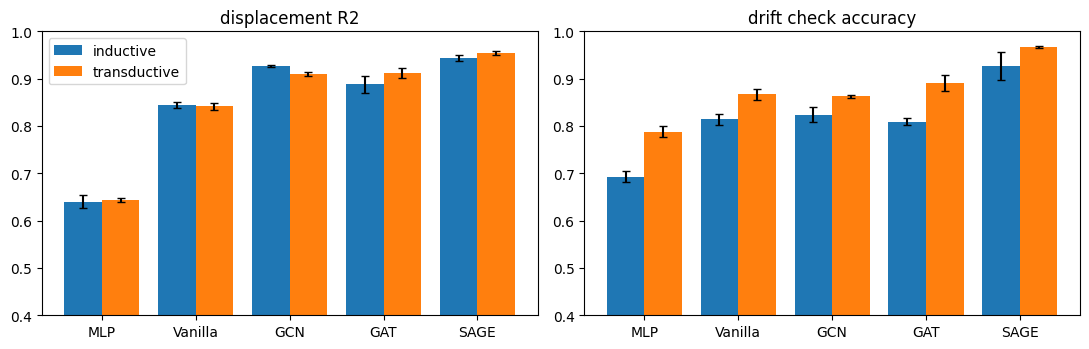

In [31]:
names, pos = list(LAYERS), np.arange(len(LAYERS))      # 모델 이름 · 막대 위치
panels = [(ind_reg, tra_reg, "displacement R2"),       # 왼쪽: 변위 결정계수
          (ind_cls, tra_cls, "drift check accuracy")]  # 오른쪽: 1/400 검토 정확도
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))      # 그림 두 개
for ax, (a, b, title) in zip(axes, panels):            # 지표마다
    for k, (res, lab) in enumerate([(a, "inductive"), (b, "transductive")]):  # 두 설정
        m = [res[n].mean().item() for n in names]      # 평균
        s = [res[n].std().item() for n in names]       # 표준편차 (오차 막대)
        ax.bar(pos + (k - 0.5) * 0.4, m, 0.4, yerr=s, capsize=3, label=lab)  # 막대
    ax.set_xticks(pos, names); ax.set_title(title); ax.set_ylim(0.4, 1.0)  # 축 · 제목
axes[0].legend(); plt.tight_layout(); plt.show()       # 범례 · 그리기

🔍 **결과 읽는 법 — 확인한 것 / 아직 주장하지 않는 것**
- **확인한 것**: ① 네 모델 모두 MLP 보다 높습니다 (두 설정 · 두 지표). ② GraphSAGE 가 두 설정 · 두 지표 모두 가장 높습니다 (seed 3개 모두). ③ 검토 정확도는 다섯 모델 모두 전이 쪽이 높지만, 변위 $R^2$ 는 두 설정이 비슷합니다 — 시험 절점의 묶음이 달라 $R^2$ 를 그대로 비교하기도 어렵습니다.
- **아직 주장하지 않는 것**: GraphSAGE 가 앞선 **이유**. 자기 피처와 이웃 평균을 따로 섞는 구조(강의노트의 B · D 이야기)가 한 가지 후보지만, 이 실험만으로는 확인하지 않았습니다. VanillaGNN · GCN · GAT 사이의 순위도 설정에 따라 바뀝니다.
- 숫자를 읽을 때: **전이 점수가 높다고 더 좋은 모델이 아닙니다.** 실제로 쓸 상황(새 건물인가, 센서를 단 건물인가)에 맞는 설정의 점수를 보세요.

---
## 7. 핵심 요약

### 이론 ↔ 코드 대응표
| 이론 (강의노트) | PyG · PyTorch 코드 |
|---|---|
| 골조 = 그래프 (절점 · 부재) | `frame_edges(nb, ns)` → `edge_index` · 피처 `[지지?, 하중, 아래 기둥 강성, 높이]` |
| 전단빌딩 손계산 | `k = 12EI/h³` · `V = cumsum(F[::-1])[::-1]` · `δ = V / Σk` · `u = cumsum(δ)` |
| VanillaGNN · GCN · GAT · SAGE 한 층 | `A_tilde @ x` · `GCNConv` · `GATConv` (`att_dst` · `att_src`) · `SAGEConv` (`lin_r` · `lin_l`) |
| 희소 인접행렬 | `torch.sparse_coo_tensor(idx, ones, (n, n))` — 1 이 있는 칸만 저장 |
| 여러 그래프 학습 | `Batch.from_data_list(...)` — 떨어진 그래프들을 큰 그래프 하나로 |
| 귀납 vs 전이 | 건물 단위로 나누기 (280 / 60 / 60동) vs 같은 그래프에서 절점 70 % / 15 % |
| 지표 | 변위 결정계수 $R^2$ · 1/400 검토 정확도 (기준: 늘 '만족') |

### 학습 루프 4단계 (지난 실습과 같은 뼈대!)
```python
out = model(*inputs)                     # 1️⃣ 순전파 (모든 절점)
loss = loss_fn(task, out, b, mask)       # 2️⃣ 채점할 절점만 오차
opt.zero_grad(); loss.backward()         # 3️⃣ 역전파
opt.step()                               # 4️⃣ 가중치 업데이트
```

### ⚠️ 자주 하는 실수 5가지
1. 지지 절점까지 채점 → 늘 0 인 값을 맞혀 점수가 부풀려집니다. **지지가 아닌 절점만** (`lev > 0`).
2. 전체 400동으로 표준화 → 시험 건물을 미리 본 셈입니다. 평균 · 표준편차는 **학습 건물에서만**.
3. 절점 단위로 무작위로 나누고 "새 건물에도 된다"고 말하기 → 그건 전이 설정입니다. 새 건물은 **건물 단위로** 나눠야 확인됩니다.
4. 보를 엣지에서 빠뜨림 → 같은 레벨의 절점끼리 정보가 오가지 않습니다. 부재는 **기둥과 보 모두**.
5. 희소 $\tilde A$ 에 자기 루프를 빠뜨림 → VanillaGNN 이 자기 피처를 잃습니다.

### 🏆 도전 과제
1. 층 수를 3 → 5 로 바꿔 보세요 (`sizes=(4, 32, 32, 32, 32)`). 5층 건물에서 지붕 하중이 1층 절점까지 오려면 몇 홉이 필요할까요?
2. `SAGEConv(..., root_weight=False)` 로 자기 항을 없애면 GraphSAGE 의 점수가 어떻게 바뀌는지 seed 3개로 확인해 보세요 — GraphSAGE 가 앞선 이유의 한 가지 시험입니다.
3. 검증 60동(`val_f`)으로 에포크 수 또는 은닉 크기를 고른 뒤, 시험 60동에서 한 번만 평가해 보세요.

### 이 실습의 단순화
- 전단빌딩 가정(강체 보 · 고정 기둥)이라 손계산이 가능합니다. 실제 골조는 보가 휘고 절점이 회전하므로 직접강성법이 필요합니다.
- 모든 모델에 같은 설정(층 3 · 은닉 32 · 300 에포크 · 드롭아웃 없음)을 씁니다. 모델마다 설정을 맞추면 순위가 바뀔 수 있습니다.

### 다음 실습 예고
노드 하나하나를 맞히는 노드 단위 문제를 다뤘습니다. 다음에는 그래프 **전체**의 성질(예: 건물 전체의 최대 층간변위)을 맞히는 **그래프 단위** 문제와 표현력(GIN)을 다룹니다.